In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto sólo se conserva la matriz de Zaderenko sin calcular: en la casilla (i, j) figura la actividad que va del nodo i al nodo j y, entre paréntesis, su duración en días; las ficticias aparecen como tales. Los nodos están numerados de modo que todo arco va de un número menor a uno mayor.

In [4]:
#| tbl-cap: "Matriz de Zaderenko del enunciado"
#| label: tbl-matrizEnunciado
matriz_enunciado = pd.DataFrame('', index=['1', '2', '3', '4', '5', '6', '7', '8'], columns=['1', '2', '3', '4', '5', '6', '7', '8'])
matriz_enunciado.loc['1', '2'] = 'B (5)'
matriz_enunciado.loc['1', '3'] = 'A (5)'
matriz_enunciado.loc['2', '4'] = 'ficticia'
matriz_enunciado.loc['2', '5'] = 'D (6)'
matriz_enunciado.loc['3', '4'] = 'ficticia'
matriz_enunciado.loc['3', '7'] = 'E (3)'
matriz_enunciado.loc['4', '5'] = 'C (6)'
matriz_enunciado.loc['5', '6'] = 'F (2)'
matriz_enunciado.loc['6', '7'] = 'ficticia'
matriz_enunciado.loc['6', '8'] = 'H (8)'
matriz_enunciado.loc['7', '8'] = 'G (5)'
matriz_enunciado.index.name = 'nodo'
matriz_enunciado

,1,2,3,4,5,6,7,8
nodo,,,,,,,,
1,,B (5),A (5),,,,,
2,,,,ficticia,D (6),,,
3,,,,ficticia,,,E (3),
4,,,,,C (6),,,
5,,,,,,F (2),,
6,,,,,,,ficticia,H (8)
7,,,,,,,,G (5)
8,,,,,,,,


In [5]:
pregunta_1 = "1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  "
pregunta_2 = "2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  "
pregunta_3 = "3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  "
pregunta_4 = "4. Obtenga el calendario de las actividades y el camino crítico.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  

2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  

3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  

4. Obtenga el calendario de las actividades y el camino crítico.  

# Resolución

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  

Cada casilla no vacía es un arco (i → j). Las predecesoras de una actividad que sale del nodo i son las actividades que entran en i, más las que entran en los nodos desde los que llega una ficticia a i (siguiendo las cadenas de ficticias hacia atrás).

In [7]:
arcos = {}
for i in matriz_enunciado.index:
    for j in matriz_enunciado.columns:
        txt = matriz_enunciado.loc[i, j]
        if txt:
            arcos[(i, j)] = ('ficticia' if txt == 'ficticia' else txt.split(' ')[0], 0 if txt == 'ficticia' else int(txt.split('(')[1].rstrip(')')))
def entran(nodo):
    acts = set()
    for (i, j), (nombre, _) in arcos.items():
        if j == nodo:
            acts |= {nombre} if nombre != 'ficticia' else entran(i)
    return acts
prelaciones_dict, duraciones = {}, {}
for (i, j), (nombre, d) in arcos.items():
    if nombre != 'ficticia':
        prelaciones_dict[nombre] = ','.join(sorted(entran(i))) or '---'
        duraciones[nombre] = d
datos_proyecto = pd.DataFrame({'predecessor': pd.Series(prelaciones_dict), 'duration': pd.Series(duraciones)}).sort_index()
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor,duration
activity,,
A,---,5
B,---,5
C,"A,B",6
D,B,6
E,A,3
F,"C,D",2
G,"E,F",5
H,F,8


## Apartado 2

In [8]:
display(Markdown(pregunta_2))

2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  

In [9]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

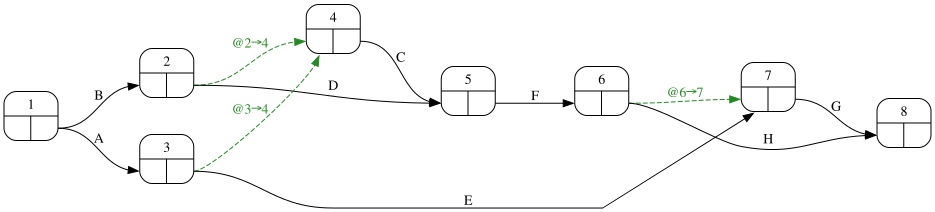

In [10]:
#| fig-cap: "Grafo PERT reconstruido"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

La numeración de los nodos puede diferir de la del enunciado (hay varias numeraciones válidas), pero la matriz tiene las mismas actividades en las mismas posiciones relativas.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  

In [12]:
#| tbl-cap: "Matriz de Zaderenko calculada"
#| label: tbl-zaderenko
proyecto.zaderenko(durations=datos_proyecto['duration'])

,1,2,3,4,5,6,7,8,early
1,,5.0,5.0,,,,,,0.0
2,,,,0.0,6.0,,,,5.0
3,,,,0.0,,,3.0,,5.0
4,,,,,6.0,,,,5.0
5,,,,,,2.0,,,11.0
6,,,,,,,0.0,8.0,13.0
7,,,,,,,,5.0,13.0
8,,,,,,,,,21.0
late,0.0,5.0,5.0,5.0,11.0,13.0,16.0,21.0,


In [13]:
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
display(resultados_pert['nodes'].T)
Markdown(f'La duración del proyecto es {proyecto.duration(datos_proyecto["duration"])} días.')

,1,2,3,4,5,6,7,8
early,0,5,5,5,11,13,13,21
late,0,5,5,5,11,13,16,21


La duración del proyecto es 21 días.

Cada tiempo temprano es el máximo, sobre los arcos que llegan al nodo, de «tiempo temprano del origen + duración del arco»; cada tiempo tardío, el mínimo, sobre los arcos que salen, de «tiempo tardío del destino − duración». Las ficticias (@) aportan duración 0. Las tablas recogen los candidatos que se comparan en cada nodo.

In [14]:
#| tbl-cap: "Tiempos tempranos: candidatos en cada nodo (de izquierda a derecha)"
#| label: tbl-tempranosPaso
tiempos_tempranos, tiempos_tardios = detalle_tiempos_nodos(proyecto, datos_proyecto['duration'])
tiempos_tempranos

,candidatos t_i + d_ij,tiempo temprano = máx
nodo,,
1,nodo inicial,0
2,B: 0 + 5 = 5,5
3,A: 0 + 5 = 5,5
4,@2→4: 5 + 0 = 5; @3→4: 5 + 0 = 5,5
5,D: 5 + 6 = 11; C: 5 + 6 = 11,11
6,F: 11 + 2 = 13,13
7,E: 5 + 3 = 8; @6→7: 13 + 0 = 13,13
8,H: 13 + 8 = 21; G: 13 + 5 = 18,21


In [15]:
#| tbl-cap: "Tiempos tardíos: candidatos en cada nodo (de derecha a izquierda)"
#| label: tbl-tardiosPaso
tiempos_tardios

,candidatos t*_j − d_ij,tiempo tardío = mín
nodo,,
8,nodo final (= su tiempo temprano),21
7,G: 21 − 5 = 16,16
6,@6→7: 16 − 0 = 16; H: 21 − 8 = 13,13
5,F: 13 − 2 = 11,11
4,C: 11 − 6 = 5,5
3,@3→4: 5 − 0 = 5; E: 16 − 3 = 13,5
2,@2→4: 5 − 0 = 5; D: 11 − 6 = 5,5
1,B: 5 − 5 = 0; A: 5 − 5 = 0,0


## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Obtenga el calendario de las actividades y el camino crítico.  

In [17]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
proyecto.calendar(datos_proyecto['duration'])[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,5,0,5,0
B,0,5,0,5,0
C,5,11,5,11,0
D,5,11,5,11,0
E,5,8,13,16,8
F,11,13,11,13,0
G,13,18,16,21,3
H,13,21,13,21,0


In [18]:
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])

- Route_2 :	A, C, F, H <br> 

- Route_5 :	B, C, F, H <br> 

- Route_7 :	B, D, F, H <br> 